<a href="https://colab.research.google.com/github/anishnath02/scg-classification/blob/main/SCG_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import numpy as np
import scipy.io as sio
import scipy.signal as signal
import matplotlib.pyplot as plt
import pandas as pd

In [9]:
from google.colab import files

uploaded = files.upload()

Saving CP-01-ECG.mat to CP-01-ECG (1).mat
Saving CP-01-SCG.mat to CP-01-SCG (1).mat
Saving CP-01-Vectors.mat to CP-01-Vectors (1).mat


In [10]:
import scipy.io as sio

for filename in uploaded:
    data = sio.loadmat(filename)
    print(f"\n{filename}")
    print(data.keys())


CP-01-ECG (1).mat
dict_keys(['__header__', '__version__', '__globals__', 'data', '__function_workspace__'])

CP-01-SCG (1).mat
dict_keys(['__header__', '__version__', '__globals__', 'data', '__function_workspace__'])

CP-01-Vectors (1).mat
dict_keys(['__header__', '__version__', '__globals__', 'Shimmer_D0CD_Accel_LN_X_CAL1', 'Shimmer_D0CD_Accel_LN_Y_CAL1', 'Shimmer_D0CD_Accel_LN_Z_CAL1', 'Shimmer_D0CD_ECG_EMG_Status1_CAL1', 'Shimmer_D0CD_ECG_EMG_Status2_CAL1', 'Shimmer_D0CD_ECG_LARA_24BIT_CAL1', 'Shimmer_D0CD_ECG_LLLA_24BIT_CAL1', 'Shimmer_D0CD_ECG_LLRA_24BIT_CAL1', 'Shimmer_D0CD_ECG_VxRL_24BIT_CAL1', 'Shimmer_D0CD_Gyro_X_CAL1', 'Shimmer_D0CD_Gyro_Y_CAL1', 'Shimmer_D0CD_Gyro_Z_CAL1', 'Shimmer_D0CD_Timestamp_Shimmer_CAL1', 'None', '__function_workspace__'])


In [11]:
import scipy.io as sio
import numpy as np

filenames = [
    "CP-01-Vectors.mat",
    "CP-01-ECG.mat",
    "CP-01-SCG.mat"
]

for filename in filenames:
    data = sio.loadmat(filename)

    print(f"\n{'='*50}")
    print("FILE:", filename)

    for key, value in data.items():
        if not key.startswith("__"):
            print(f"{key}: shape={np.shape(value)}, dtype={getattr(value, 'dtype', type(value))}")


FILE: CP-01-Vectors.mat
Shimmer_D0CD_Accel_LN_X_CAL1: shape=(124838, 1), dtype=float64
Shimmer_D0CD_Accel_LN_Y_CAL1: shape=(124838, 1), dtype=float64
Shimmer_D0CD_Accel_LN_Z_CAL1: shape=(124838, 1), dtype=float64
Shimmer_D0CD_ECG_EMG_Status1_CAL1: shape=(124838, 1), dtype=uint8
Shimmer_D0CD_ECG_EMG_Status2_CAL1: shape=(124838, 1), dtype=uint8
Shimmer_D0CD_ECG_LARA_24BIT_CAL1: shape=(124838, 1), dtype=float64
Shimmer_D0CD_ECG_LLLA_24BIT_CAL1: shape=(124838, 1), dtype=float64
Shimmer_D0CD_ECG_LLRA_24BIT_CAL1: shape=(124838, 1), dtype=float64
Shimmer_D0CD_ECG_VxRL_24BIT_CAL1: shape=(124838, 1), dtype=float64
Shimmer_D0CD_Gyro_X_CAL1: shape=(124838, 1), dtype=float64
Shimmer_D0CD_Gyro_Y_CAL1: shape=(124838, 1), dtype=float64
Shimmer_D0CD_Gyro_Z_CAL1: shape=(124838, 1), dtype=float64
Shimmer_D0CD_Timestamp_Shimmer_CAL1: shape=(124838, 1), dtype=float64
None: shape=(1,), dtype=[('s0', 'O'), ('s1', 'O'), ('s2', 'O'), ('arr', 'O')]

FILE: CP-01-ECG.mat
data: shape=(1, 1), dtype=[('R_loc', 'O'

In [12]:
import scipy.io as sio
import numpy as np

for filename in ["CP-01-ECG.mat", "CP-01-SCG.mat"]:

    mat = sio.loadmat(filename)
    struct = mat["data"][0, 0]

    print("\n" + "="*50)
    print("FILE:", filename)

    for field in ["R_loc", "RR_int"]:

        values = struct[field]

        print(f"\n{field}")
        print("Shape:", values.shape)
        print("Data type:", values.dtype)

        for i, item in enumerate(np.ravel(values)):
            print(f"Element {i}:")
            print("  Type:", type(item))
            print("  Shape:", np.shape(item))
            print("  Value preview:", repr(item)[:300])


FILE: CP-01-ECG.mat

R_loc
Shape: (1, 3)
Data type: object
Element 0:
  Type: <class 'scipy.io.matlab._mio5_params.MatlabOpaque'>
  Shape: (1,)
  Value preview: MatlabOpaque([(b'', b'MCOS', b'duration', array([[3707764736],
                     [         2],
                     [         1],
                     [         1],
                     [         1],
                     [         1]], dtype=uint32))            ],
             dtype=[('s0', 'O'),
Element 1:
  Type: <class 'scipy.io.matlab._mio5_params.MatlabOpaque'>
  Shape: (1,)
  Value preview: MatlabOpaque([(b'', b'MCOS', b'duration', array([[3707764736],
                     [         2],
                     [         1],
                     [         1],
                     [         2],
                     [         1]], dtype=uint32))            ],
             dtype=[('s0', 'O'),
Element 2:
  Type: <class 'scipy.io.matlab._mio5_params.MatlabOpaque'>
  Shape: (1,)
  Value preview: MatlabOpaque([(b'', b'MCOS', b'd

In [13]:
mat = sio.loadmat("CP-01-Vectors.mat")

timestamp = mat["Shimmer_D0CD_Timestamp_Shimmer_CAL1"].flatten()

print("First 10 timestamps:", timestamp[:10])

diff = np.diff(timestamp)

print("Median timestamp difference:", np.median(diff))
print("Estimated sampling frequency:", 1 / np.median(diff))
print("Duration (seconds):", len(timestamp) / 256)
print("Duplicate timestamps:", np.sum(diff == 0))

First 10 timestamps: [12056.73217773 12064.54467773 12068.45092773 12072.35717773
 12076.26342773 12080.16967773 12084.07592773 12087.98217773
 12091.88842773 12095.79467773]
Median timestamp difference: 3.90625
Estimated sampling frequency: 0.256
Duration (seconds): 487.6484375
Duplicate timestamps: 0


## **Next: visualize ECG and SCG signals**

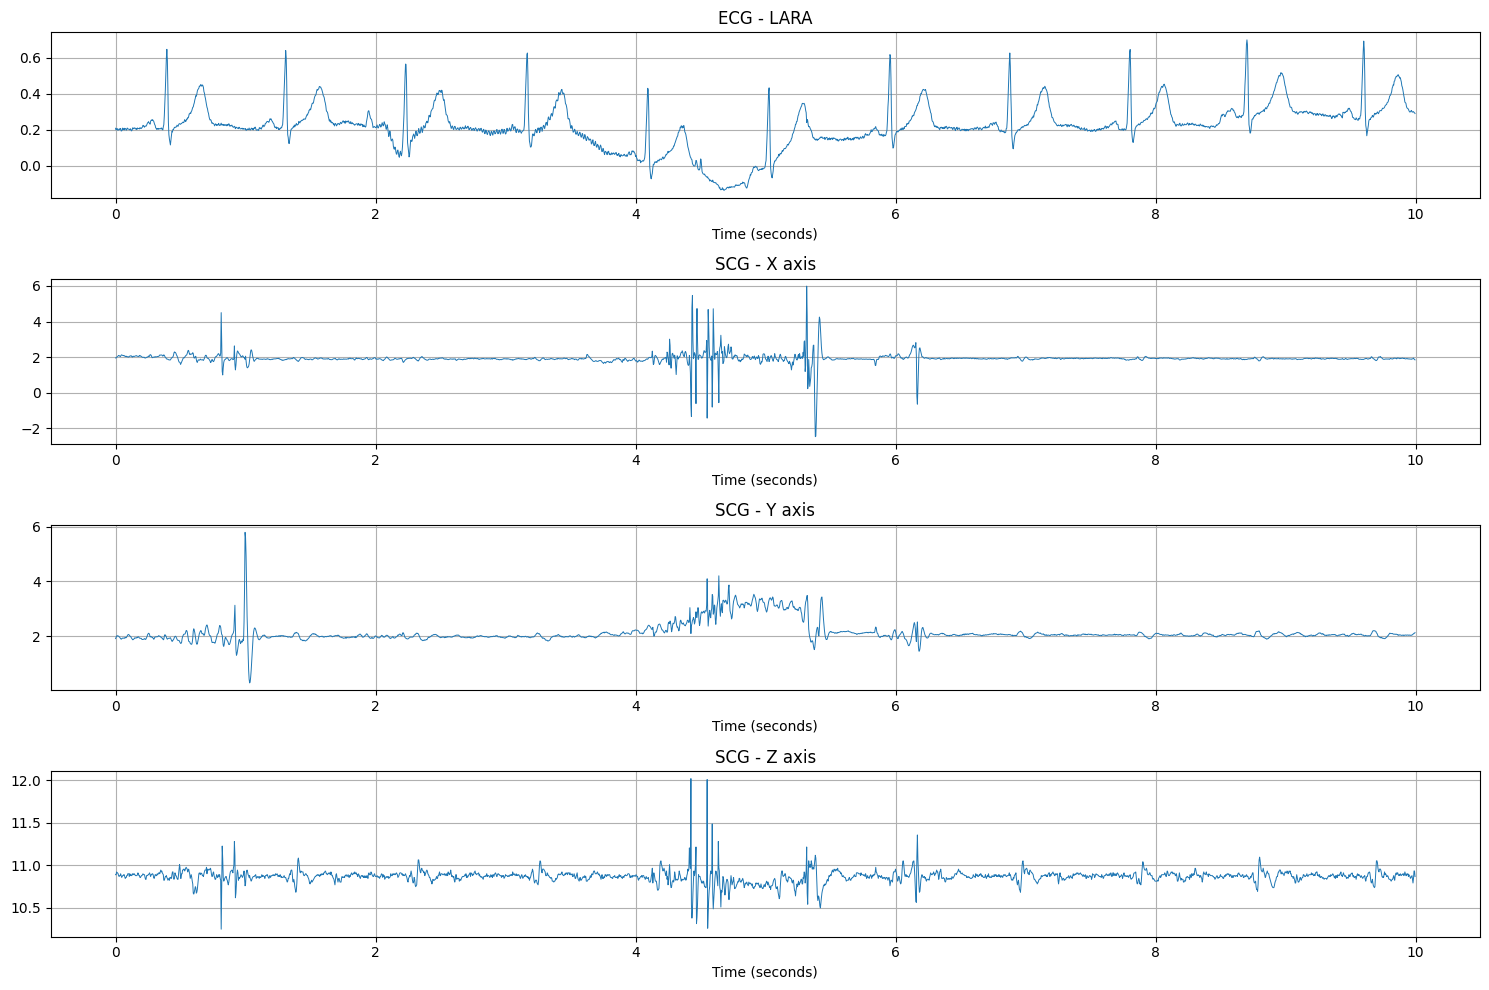

In [14]:
import scipy.io as sio
import numpy as np
import matplotlib.pyplot as plt

data = sio.loadmat("CP-01-Vectors.mat")

fs = 256
duration = 10
n = fs * duration

# ECG channel
ecg = data["Shimmer_D0CD_ECG_LARA_24BIT_CAL1"].flatten()

# SCG channels
scg_x = data["Shimmer_D0CD_Accel_LN_X_CAL1"].flatten()
scg_y = data["Shimmer_D0CD_Accel_LN_Y_CAL1"].flatten()
scg_z = data["Shimmer_D0CD_Accel_LN_Z_CAL1"].flatten()

time = np.arange(n) / fs

fig, axes = plt.subplots(4, 1, figsize=(15, 10))

signals = [
    (ecg, "ECG - LARA"),
    (scg_x, "SCG - X axis"),
    (scg_y, "SCG - Y axis"),
    (scg_z, "SCG - Z axis")
]

for ax, (sig, title) in zip(axes, signals):
    ax.plot(time, sig[:n], linewidth=0.7)
    ax.set_title(title)
    ax.set_xlabel("Time (seconds)")
    ax.grid(True)

plt.tight_layout()
plt.show()

## **RR intervals**

In [15]:
for filename in ["CP-01-ECG.mat", "CP-01-SCG.mat"]:
    mat = sio.loadmat(filename)
    rr = mat["data"][0, 0]["RR_int"]

    print("\n", filename)

    for i, channel in enumerate(rr.flatten()):
        values = np.asarray(channel).flatten()

        print(
            f"Channel {i+1}: "
            f"Count={len(values)}, "
            f"Mean={np.mean(values):.2f} ms, "
            f"Min={np.min(values):.2f} ms, "
            f"Max={np.max(values):.2f} ms"
        )


 CP-01-ECG.mat
Channel 1: Count=522, Mean=882.37 ms, Min=707.03 ms, Max=933.59 ms
Channel 2: Count=522, Mean=882.38 ms, Min=707.03 ms, Max=933.59 ms
Channel 3: Count=522, Mean=882.38 ms, Min=707.03 ms, Max=937.50 ms

 CP-01-SCG.mat
Channel 1: Count=521, Mean=882.30 ms, Min=679.69 ms, Max=1097.66 ms
Channel 2: Count=521, Mean=882.29 ms, Min=574.22 ms, Max=1207.03 ms
Channel 3: Count=521, Mean=882.31 ms, Min=699.22 ms, Max=1000.00 ms


## **preprocessing**

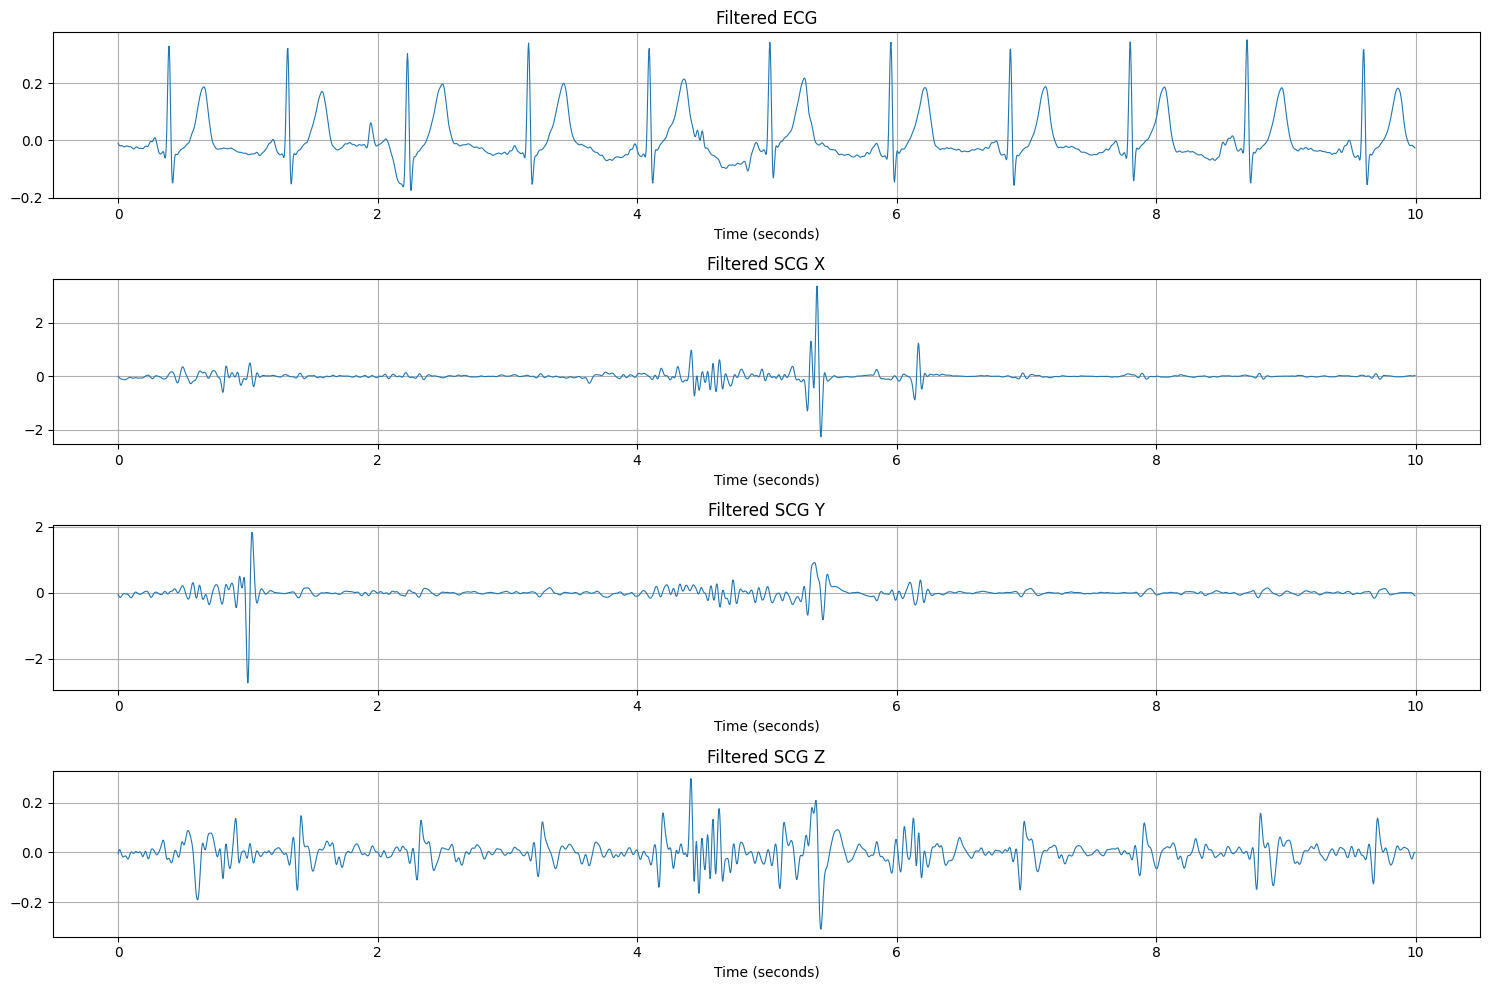

In [16]:
from scipy.signal import butter, sosfiltfilt
import numpy as np
import matplotlib.pyplot as plt
import scipy.io as sio

data = sio.loadmat("CP-01-Vectors.mat")

fs = 256

# Load ECG
ecg = data["Shimmer_D0CD_ECG_LARA_24BIT_CAL1"].flatten()

# Load and correct SCG axes
scg_x = -data["Shimmer_D0CD_Accel_LN_X_CAL1"].flatten()
scg_y = -data["Shimmer_D0CD_Accel_LN_Y_CAL1"].flatten()
scg_z = data["Shimmer_D0CD_Accel_LN_Z_CAL1"].flatten()

# Butterworth bandpass filtering
def bandpass_filter(signal_data, low, high, fs, order=4):
    sos = butter(
        order,
        [low, high],
        btype="bandpass",
        fs=fs,
        output="sos"
    )
    return sosfiltfilt(sos, signal_data)

# Filter signals
ecg_filtered = bandpass_filter(ecg, 0.8, 30, fs)

scg_x_filtered = bandpass_filter(scg_x, 0.8, 25, fs)
scg_y_filtered = bandpass_filter(scg_y, 0.8, 25, fs)
scg_z_filtered = bandpass_filter(scg_z, 0.8, 25, fs)

# Plot first 10 seconds
n = 10 * fs
t = np.arange(n) / fs

signals = [
    (ecg_filtered, "Filtered ECG"),
    (scg_x_filtered, "Filtered SCG X"),
    (scg_y_filtered, "Filtered SCG Y"),
    (scg_z_filtered, "Filtered SCG Z")
]

fig, axes = plt.subplots(4, 1, figsize=(15, 10))

for ax, (sig, title) in zip(axes, signals):
    ax.plot(t, sig[:n], linewidth=0.8)
    ax.set_title(title)
    ax.set_xlabel("Time (seconds)")
    ax.grid(True)

plt.tight_layout()
plt.show()

## **ECG R-peak detection**

Detected R-peaks: 552
Mean RR: 883.0535390199638 ms
Mean heart rate: 67.9460500963391 BPM


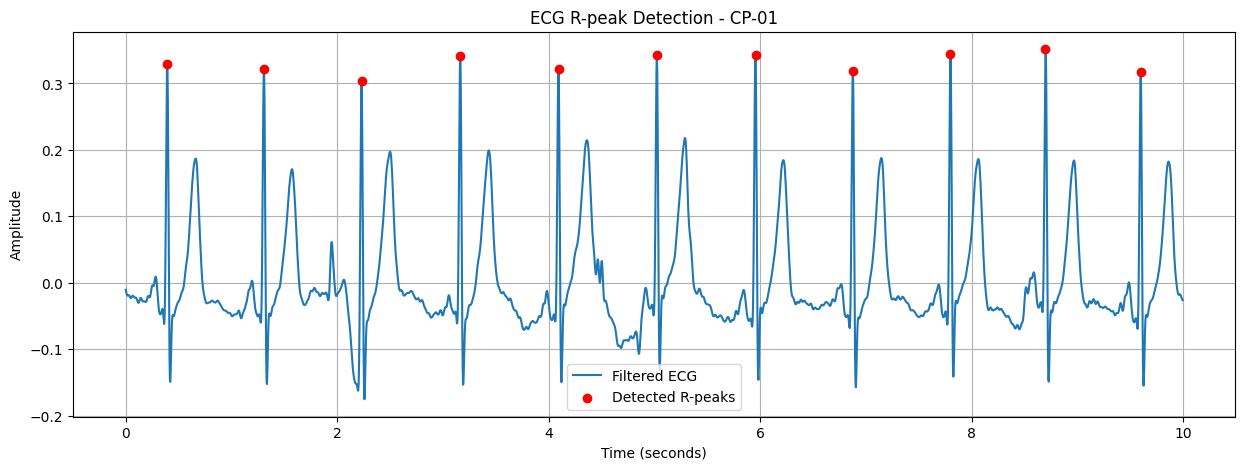

In [17]:
from scipy.signal import find_peaks
import numpy as np
import matplotlib.pyplot as plt

# Detect R-peaks
peaks, properties = find_peaks(
    ecg_filtered,
    distance=int(0.45 * fs),
    prominence=0.08
)

# Calculate RR intervals
rr_detected = np.diff(peaks) / fs * 1000

print("Detected R-peaks:", len(peaks))
print("Mean RR:", np.mean(rr_detected), "ms")
print("Mean heart rate:", 60000 / np.mean(rr_detected), "BPM")

# Plot first 10 seconds
n = 10 * fs
t = np.arange(n) / fs

plt.figure(figsize=(15, 5))
plt.plot(t, ecg_filtered[:n], label="Filtered ECG")
visible_peaks = peaks[peaks < n]

plt.scatter(
    visible_peaks / fs,
    ecg_filtered[visible_peaks],
    color="red",
    label="Detected R-peaks",
    zorder=3
)

plt.title("ECG R-peak Detection - CP-01")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()

DETECTED RR
Count: 551
Mean: 883.0535390199638
Median: 882.8125
Min: 707.03125
Max: 1031.25

REFERENCE RR
Count: 522
Mean: 882.3709889846743
Median: 882.8125
Min: 707.03125
Max: 933.59375


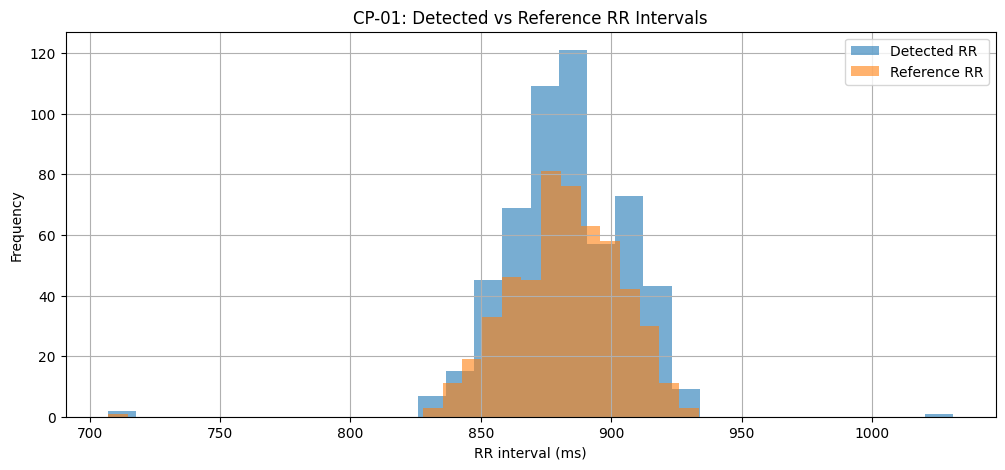

In [18]:
import scipy.io as sio
import numpy as np
import matplotlib.pyplot as plt

# Detected RR intervals
detected_rr = np.diff(peaks) / fs * 1000

# Supplied ECG RR intervals
mat = sio.loadmat("CP-01-ECG.mat")
rr_data = mat["data"][0, 0]["RR_int"]

reference_rr = np.asarray(rr_data[0, 0]).flatten()

print("DETECTED RR")
print("Count:", len(detected_rr))
print("Mean:", np.mean(detected_rr))
print("Median:", np.median(detected_rr))
print("Min:", np.min(detected_rr))
print("Max:", np.max(detected_rr))

print("\nREFERENCE RR")
print("Count:", len(reference_rr))
print("Mean:", np.mean(reference_rr))
print("Median:", np.median(reference_rr))
print("Min:", np.min(reference_rr))
print("Max:", np.max(reference_rr))

# Compare distributions
plt.figure(figsize=(12, 5))

plt.hist(detected_rr, bins=30, alpha=0.6, label="Detected RR")
plt.hist(reference_rr, bins=30, alpha=0.6, label="Reference RR")

plt.xlabel("RR interval (ms)")
plt.ylabel("Frequency")
plt.title("CP-01: Detected vs Reference RR Intervals")
plt.legend()
plt.grid(True)
plt.show()

## **investigate the discrepancy**

In [19]:
import numpy as np
import scipy.io as sio

# Load reference RR intervals
mat = sio.loadmat("CP-01-ECG.mat")
rr_data = mat["data"][0, 0]["RR_int"]

reference_rr = np.asarray(rr_data[0, 0]).flatten()

# Detected RR intervals
detected_rr = np.diff(peaks) / fs * 1000

# Cumulative elapsed time
detected_time = np.cumsum(detected_rr) / 1000
reference_time = np.cumsum(reference_rr) / 1000

print("Detected sequence duration:", detected_time[-1], "seconds")
print("Reference sequence duration:", reference_time[-1], "seconds")

print("\nFirst 20 detected RR:")
print(np.round(detected_rr[:20], 2))

print("\nFirst 20 reference RR:")
print(np.round(reference_rr[:20], 2))

print("\nLast 10 detected RR:")
print(np.round(detected_rr[-10:], 2))

print("\nLast 10 reference RR:")
print(np.round(reference_rr[-10:], 2))

Detected sequence duration: 486.5625 seconds
Reference sequence duration: 460.59765625 seconds

First 20 detected RR:
[917.97 921.88 933.59 929.69 929.69 933.59 921.88 921.88 898.44 902.34
 890.62 894.53 886.72 890.62 878.91 890.62 894.53 882.81 882.81 890.62]

First 20 reference RR:
[890.62 894.53 886.72 890.62 878.91 890.62 894.53 882.81 882.81 890.62
 867.19 882.81 871.09 859.38 875.   882.81 871.09 875.   875.   843.75]

Last 10 detected RR:
[882.81 875.   867.19 882.81 875.   867.19 886.72 894.53 898.44 894.53]

Last 10 reference RR:
[921.88 917.97 906.25 914.06 906.25 914.06 917.97 902.34 921.88 914.06]


## **whether the sequences are offset**

Best detected sequence offset: 10
Best alignment MAE: 0.015 ms
Reference mean: 882.371 ms
Aligned detected mean: 882.371 ms


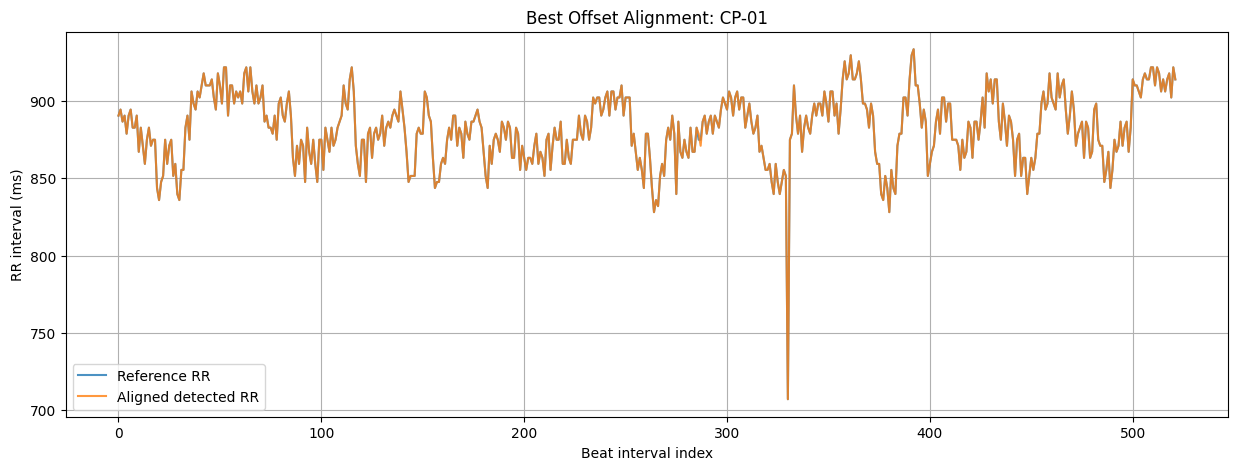

In [20]:
import numpy as np
import matplotlib.pyplot as plt

det = detected_rr
ref = reference_rr

# Find the best fixed offset
results = []

for offset in range(len(det) - len(ref) + 1):
    segment = det[offset:offset + len(ref)]
    mae = np.mean(np.abs(segment - ref))
    results.append((mae, offset))

best_mae, best_offset = min(results)

aligned_det = det[best_offset:best_offset + len(ref)]

print("Best detected sequence offset:", best_offset)
print("Best alignment MAE:", round(best_mae, 3), "ms")
print("Reference mean:", round(np.mean(ref), 3), "ms")
print("Aligned detected mean:", round(np.mean(aligned_det), 3), "ms")

plt.figure(figsize=(15, 5))
plt.plot(ref, label="Reference RR", alpha=0.8)
plt.plot(aligned_det, label="Aligned detected RR", alpha=0.8)
plt.xlabel("Beat interval index")
plt.ylabel("RR interval (ms)")
plt.title("Best Offset Alignment: CP-01")
plt.legend()
plt.grid()
plt.show()

## **inspect all three reference channels**

In [21]:
import scipy.io as sio
import numpy as np

for filename in ["CP-01-ECG.mat", "CP-01-SCG.mat"]:

    mat = sio.loadmat(filename)
    rr = mat["data"][0, 0]["RR_int"]

    print("\n", filename)

    for i in range(3):
        reference = np.asarray(rr[0, i]).flatten()

        print(
            f"Channel {i+1}: "
            f"Count={len(reference)}, "
            f"Mean={np.mean(reference):.3f} ms"
        )


 CP-01-ECG.mat
Channel 1: Count=522, Mean=882.371 ms
Channel 2: Count=522, Mean=882.378 ms
Channel 3: Count=522, Mean=882.378 ms

 CP-01-SCG.mat
Channel 1: Count=521, Mean=882.295 ms
Channel 2: Count=521, Mean=882.288 ms
Channel 3: Count=521, Mean=882.310 ms


## **SCG cardiac-cycle segmentation**

In [22]:
# Use detected ECG R-peaks to segment all SCG axes

scg_signals = {
    "X": scg_x_filtered,
    "Y": scg_y_filtered,
    "Z": scg_z_filtered
}

# Window around each ECG R-peak
pre_ms = 250
post_ms = 650

pre = int(pre_ms * fs / 1000)
post = int(post_ms * fs / 1000)

scg_cycles = {axis: [] for axis in scg_signals}

for peak in peaks:
    start = peak - pre
    end = peak + post

    if start >= 0 and end <= len(ecg_filtered):
        for axis, sig in scg_signals.items():
            scg_cycles[axis].append(sig[start:end])

for axis in scg_cycles:
    scg_cycles[axis] = np.array(scg_cycles[axis])

    print(
        f"SCG {axis}:",
        scg_cycles[axis].shape
    )

SCG X: (552, 230)
SCG Y: (552, 230)
SCG Z: (552, 230)


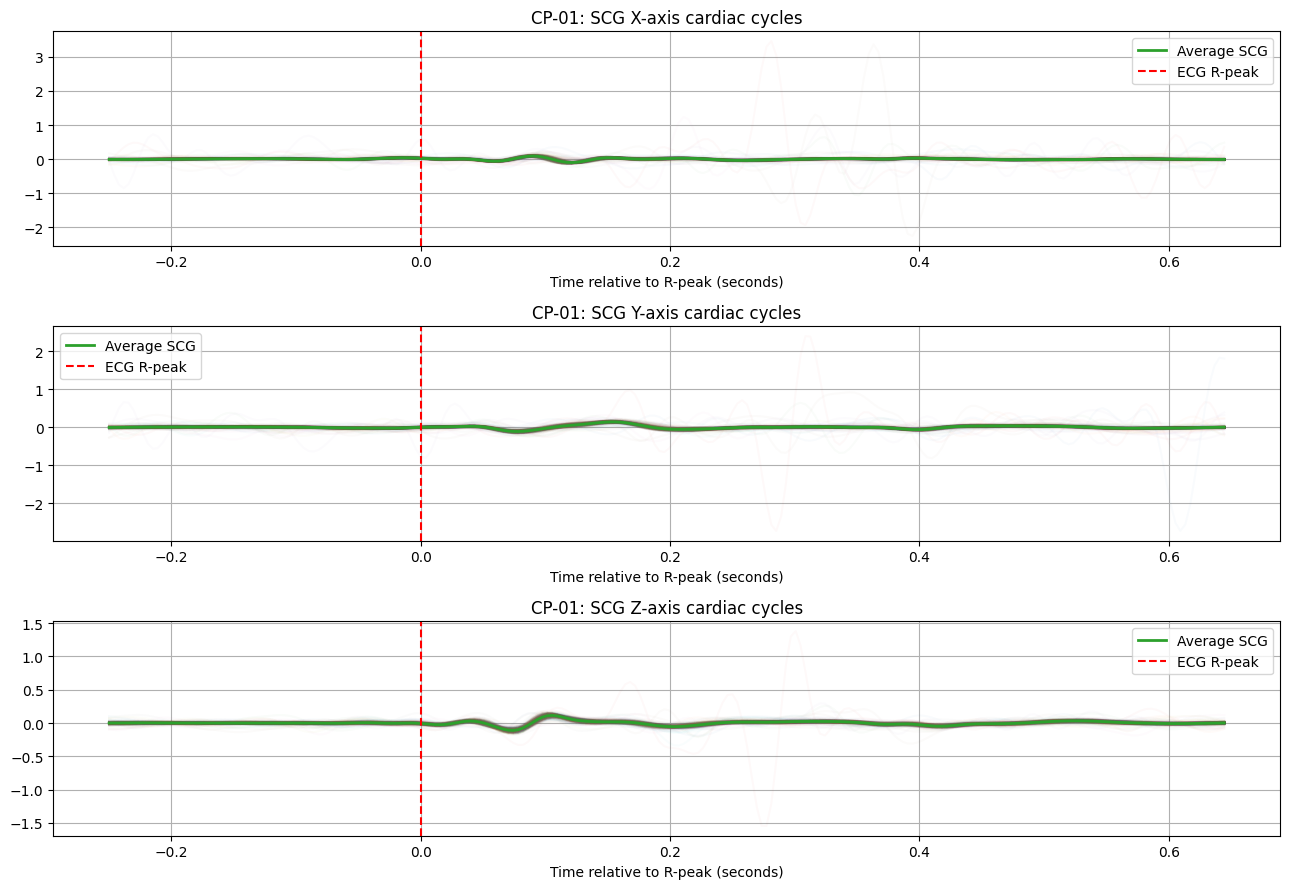

In [23]:
cycle_time = np.arange(-pre, post) / fs

fig, axes = plt.subplots(3, 1, figsize=(13, 9))

for ax, axis in zip(axes, ["X", "Y", "Z"]):

    cycles = scg_cycles[axis]

    ax.plot(cycle_time, cycles.T, alpha=0.025)
    ax.plot(
        cycle_time,
        np.mean(cycles, axis=0),
        linewidth=2,
        label="Average SCG"
    )

    ax.axvline(0, color="red", linestyle="--", label="ECG R-peak")
    ax.set_title(f"CP-01: SCG {axis}-axis cardiac cycles")
    ax.set_xlabel("Time relative to R-peak (seconds)")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

## **Mean vs Median SCG morphology**

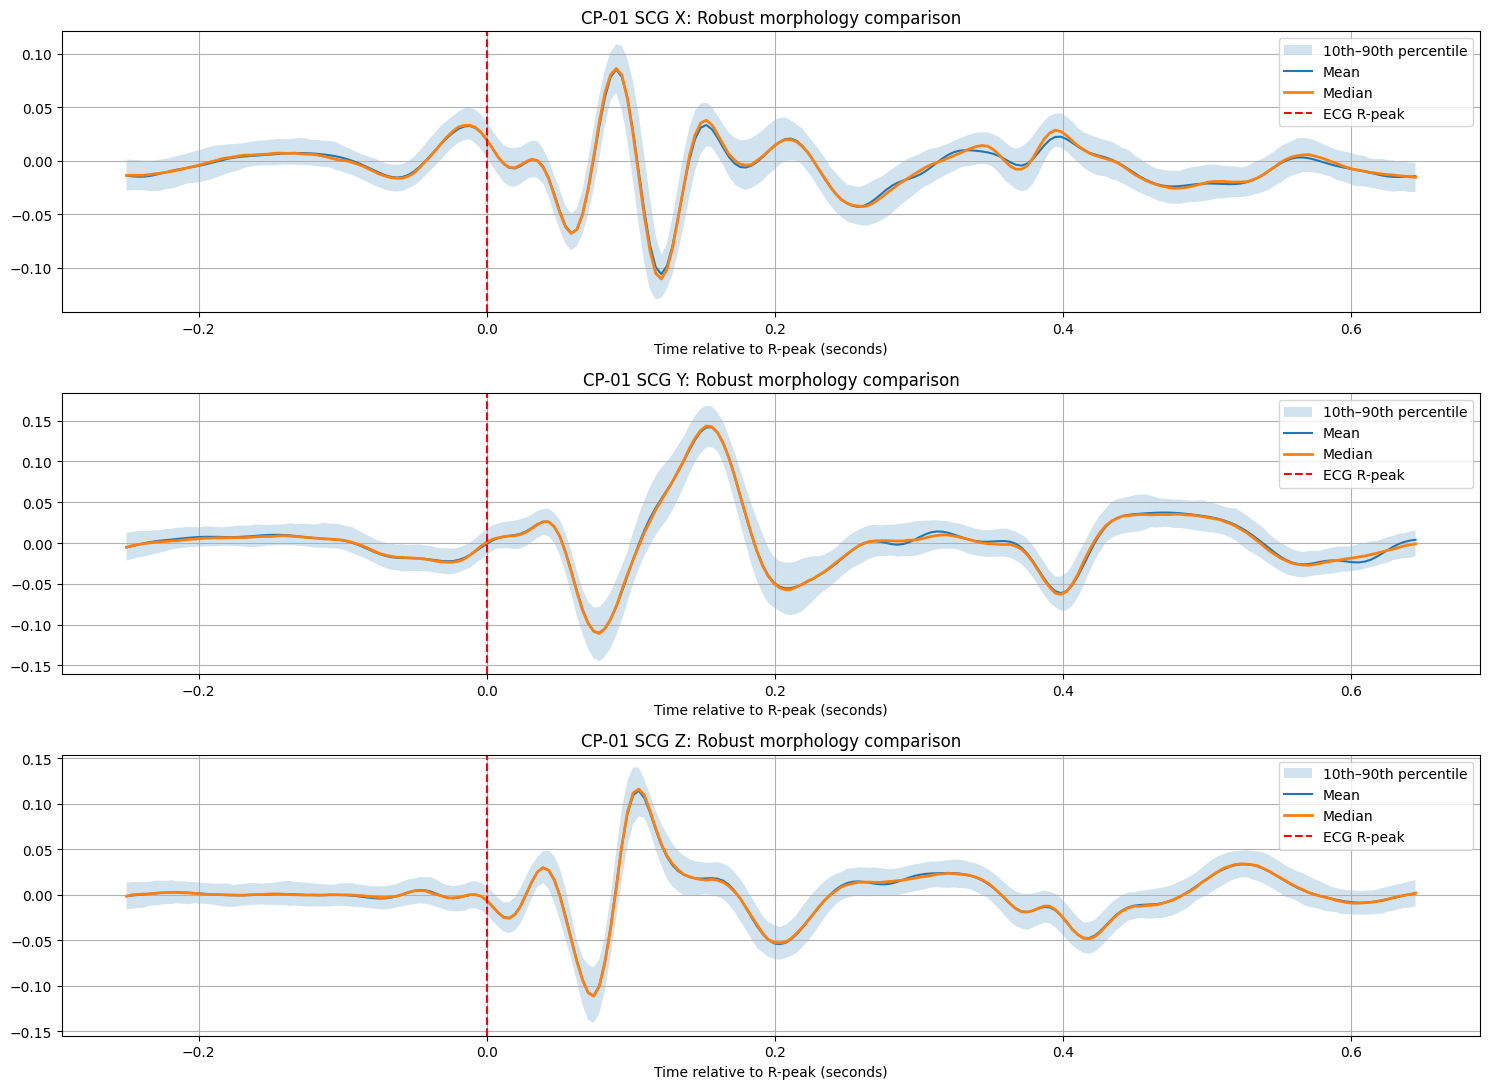

In [24]:
import numpy as np
import matplotlib.pyplot as plt

axes_names = ["X", "Y", "Z"]
cycle_time = np.arange(-pre, post) / fs

fig, plots = plt.subplots(3, 1, figsize=(15, 11))

for ax, name in zip(plots, axes_names):

    cycles = scg_cycles[name]

    # Remove each cycle's pre-R baseline offset
    baseline = np.median(cycles[:, :pre], axis=1, keepdims=True)
    corrected = cycles - baseline

    mean_wave = np.mean(corrected, axis=0)
    median_wave = np.median(corrected, axis=0)

    lower = np.percentile(corrected, 10, axis=0)
    upper = np.percentile(corrected, 90, axis=0)

    ax.fill_between(
        cycle_time, lower, upper,
        alpha=0.2, label="10th–90th percentile"
    )

    ax.plot(cycle_time, mean_wave, label="Mean", linewidth=1.5)
    ax.plot(cycle_time, median_wave, label="Median", linewidth=2)

    ax.axvline(0, color="red", linestyle="--", label="ECG R-peak")
    ax.set_title(f"CP-01 SCG {name}: Robust morphology comparison")
    ax.set_xlabel("Time relative to R-peak (seconds)")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

## **Measure cycle variability and potential artifacts**

In [25]:
for name in ["X", "Y", "Z"]:

    cycles = scg_cycles[name]

    peak_to_peak = np.ptp(cycles, axis=1)

    median_amp = np.median(peak_to_peak)
    mad = np.median(np.abs(peak_to_peak - median_amp))

    threshold = median_amp + 6 * 1.4826 * mad
    flagged = peak_to_peak > threshold

    print(f"\nSCG {name}")
    print("Median cycle amplitude:", median_amp)
    print("Maximum cycle amplitude:", np.max(peak_to_peak))
    print("Potential artifact cycles:", np.sum(flagged))
    print("Potential artifact percentage:",
          round(np.mean(flagged) * 100, 2), "%")


SCG X
Median cycle amplitude: 0.2065417626854909
Maximum cycle amplitude: 5.627276792299519
Potential artifact cycles: 23
Potential artifact percentage: 4.17 %

SCG Y
Median cycle amplitude: 0.2618659385223856
Maximum cycle amplitude: 5.140969357338459
Potential artifact cycles: 14
Potential artifact percentage: 2.54 %

SCG Z
Median cycle amplitude: 0.23417791551982461
Maximum cycle amplitude: 2.9249583963039916
Potential artifact cycles: 3
Potential artifact percentage: 0.54 %
